# Modelado Predictivo — Dengue SIN Signos de Alarma (DSSA)
## DSSA · 15,734 casos · 3.9% hospitalizados

---

## Objetivo

Construir un clasificador que prediga, al momento de la consulta inicial,
si un paciente con dengue sin signos de alarma requiere hospitalización.

El DSSA es el estrato más desafiante estadísticamente:
con solo el 3.9% de hospitalizaciones, el desbalance es severo (96/4).
Un modelo que prediga siempre 'no hospitalizar' tendrá accuracy del 96%
pero fallará en todos los casos que realmente necesitan ingreso.

## Por qué este problema es fundamentalmente diferente al DCSA

| Aspecto | DCSA | DSSA |
|---------|------|------|
| Hospitalización | 64.8% | **3.9%** |
| Desbalance | Moderado (65/35) | **Severo (96/4)** |
| Métrica primaria | F1-score | **AUC-PR** |
| SMOTE k_neighbors | 5 | **3** |
| Piso de referencia | Baseline DT | **Prevalencia (3.9%)** |
| Puntos de operación | Screening / Capacity | **Screening prioritario** |
| Riesgo clínico FN | Alto | **Crítico** |

## Decisiones metodológicas clave

| Decisión | Justificación |
|----------|---------------|
| AÑO excluido | Sesgo de período — no disponible en clínica real |
| AUC-PR como métrica primaria | Con 96/4, AUC-ROC es engañosamente alto incluso para modelos malos |
| SMOTE k=3 | Con ~600 positivos en train, k=5 genera ejemplos fuera del soporte real |
| Brier Score | Calibración crítica en DSSA: las probabilidades predichas deben ser confiables para triaje |
| Umbral ajustable | El umbral por defecto (0.5) es inapropiado con 96/4 — se analizan umbrales clínicos |



In [2]:
# ═══════════════════════════════════════════════════════════════════════════
# BANDERA DE EJECUCION
# FORZAR_RECALCULO = True  → elimina checkpoints y recalcula todo desde cero
# FORZAR_RECALCULO = False → reutiliza checkpoints existentes
# ═══════════════════════════════════════════════════════════════════════════
FORZAR_RECALCULO = True  # <-- cambia aqui

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
import joblib
import importlib
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    f1_score, roc_auc_score, balanced_accuracy_score,
    precision_score, recall_score, average_precision_score,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay,
    classification_report, make_scorer)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
if importlib.util.find_spec('catboost') is None:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'catboost'])
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore')
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelsize': 11, 'legend.frameon': False,
})
COLORS = {
    'primary': '#2C7BB6', 'secondary': '#D7191C',
    'accent': '#FDAE61', 'neutral': '#7F7F7F',
    'sin_signos': '#E74C3C', 'sin_signos': '#3498DB',
}
SIGNOS_ALARMA      = ['DOLOR_ABDO','VOMITO','DIARREA','SOMNOLENCI','HIPOTENSIO',
                      'HEPATOMEG','HEM_MUCOSA','HIPOTERMIA','AUM_HEMATO','CAIDA_PLAQ','ACUM_LIQUI']
SINTOMAS_GENERALES = ['FIEBRE','CEFALEA','DOLRRETROO','MALGIAS','ARTRALGIA','ERUPCIONR']
TARGET             = 'TARGET_HOSPITALIZACION_ORIGINAL'
RANDOM_STATE       = 42

ROOT        = Path(r'D:\Documentos\GitHub\dengue')  # <-- edita si es necesario
OUT_FIG     = ROOT / 'outputs' / 'figures'
OUT_TAB     = ROOT / 'outputs' / 'tables'
INTERIM     = ROOT / 'data' / 'interim'
CHECKPOINTS = ROOT / 'outputs' / 'checkpoints'
for p in [OUT_FIG, OUT_TAB, INTERIM, CHECKPOINTS]:
    p.mkdir(parents=True, exist_ok=True)

df = joblib.load(INTERIM / 'datos_sin_signos.pkl')
print(f'DSSA — Dengue sin signos de alarma')
print(f'  Casos    : {len(df):,}')
print(f'  Hosp.    : {df[TARGET].mean():.1%}')
print(f'  No hosp. : {1-df[TARGET].mean():.1%}')

DSSA — Dengue sin signos de alarma
  Casos    : 15,734
  Hosp.    : 3.9%
  No hosp. : 96.1%


In [3]:
import gc

def checkpoint_existe(path):
    """Respeta la bandera FORZAR_RECALCULO."""
    if FORZAR_RECALCULO:
        return False
    return Path(path).exists()

def guardar_checkpoint(obj, path, nombre=''):
    joblib.dump(obj, path)
    mb = Path(path).stat().st_size / 1e6
    print(f'  Guardado {nombre}: {Path(path).name} ({mb:.1f} MB)')

def limpiar_memoria(*objetos):
    for obj in objetos:
        try: del obj
        except: pass
    gc.collect()

def memoria_usada():
    import psutil, os
    mb = psutil.Process(os.getpid()).memory_info().rss / 1e6
    print(f'  RAM en uso: {mb:.0f} MB')

try:
    import psutil
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'psutil'])
    import psutil

# Funciones auxiliares para métricas extendidas y DCA
# Congruentes con 03a pero adaptadas a DSSA:
# - calcular_metricas_completas_dssa: incluye Brier Score y Specificity
# - decision_curve_analysis: misma implementación que 03a
# La diferencia clave es que en DSSA el Brier Score es aún más importante:
# con 3.9% de prevalencia, una mala calibración puede hacer que el modelo
# asigne P=0.03 a casos que realmente tienen P=0.30 de hospitalización

def calcular_metricas_completas_dssa(y_true, y_pred, y_prob):
    """
    Panel completo de métricas para DSSA.
    Métrica primaria: AUC-PR.
    El Brier Score es especialmente relevante en DSSA: con prevalencia 3.9%,
    un modelo mal calibrado puede subestimar sistemáticamente el riesgo real.
    """
    from sklearn.metrics import confusion_matrix, brier_score_loss
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return {
        'AUC-PR':      round(average_precision_score(y_true, y_prob), 4),
        'AUC-ROC':     round(roc_auc_score(y_true, y_prob), 4),
        'F1':          round(f1_score(y_true, y_pred), 4),
        'Brier Score': round(brier_score_loss(y_true, y_prob), 4),
        'Bal. Acc':    round(balanced_accuracy_score(y_true, y_pred), 4),
        'Precision':   round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall':      round(recall_score(y_true, y_pred), 4),
        'Specificity': round(spec, 4),
    }

def decision_curve_analysis(y_true, y_prob,
                             thresholds=np.linspace(0.01, 0.99, 99)):
    """
    DCA para DSSA. Con prevalencia 3.9%, el rango útil de umbrales
    es distinto al DCSA: el Net Benefit es relevante para pt < 0.20,
    ya que un médico difícilmente hospitalizaría si P > 0.50 en DSSA.
    """
    n = len(y_true)
    nb_model, nb_all = [], []
    for p_t in thresholds:
        y_p = (y_prob >= p_t).astype(int)
        tp  = np.sum((y_p == 1) & (y_true == 1))
        fp  = np.sum((y_p == 1) & (y_true == 0))
        nb_model.append((tp/n) - (fp/n) * (p_t / (1 - p_t)))
        tp_all = np.sum(y_true == 1)
        fp_all = np.sum(y_true == 0)
        nb_all.append((tp_all/n) - (fp_all/n) * (p_t / (1 - p_t)))
    return thresholds, np.array(nb_model), np.array(nb_all)

# Limpiar checkpoints si se fuerza recálculo
CHECKPOINTS_DSSA = [
    CHECKPOINTS / 'particion_DSSA.pkl',
    CHECKPOINTS / 'baseline_DSSA.pkl',
    CHECKPOINTS / 'cv_DSSA.pkl',
    CHECKPOINTS / 'eval_test_DSSA.pkl',
    CHECKPOINTS / 'importancia_DSSA.pkl',
    CHECKPOINTS / 'mejor_modelo_DSSA.pkl',
    CHECKPOINTS / 'operacion_clinica_DSSA.pkl',
    CHECKPOINTS / 'dca_DSSA.pkl',
    CHECKPOINTS / 'learning_curves_DSSA.pkl',
] + list(CHECKPOINTS.glob('cv_DSSA_*.pkl'))

if FORZAR_RECALCULO:
    eliminados = [cp for cp in CHECKPOINTS_DSSA if cp.exists()]
    for cp in eliminados:
        cp.unlink()
    print(f'Modo RECALCULO: {len(eliminados)} checkpoints eliminados')
else:
    existentes = [cp.name for cp in CHECKPOINTS_DSSA if cp.exists()]
    print(f'Modo REUTILIZAR: {len(existentes)} checkpoints disponibles')
    for n in existentes:
        print(f'  OK  {n}')

print('Funciones auxiliares listas: calcular_metricas_completas_dssa / decision_curve_analysis')

Modo RECALCULO: 0 checkpoints eliminados
Funciones auxiliares listas: calcular_metricas_completas_dssa / decision_curve_analysis


## 1. Preparación de features y partición

Los features son idénticos al DCSA para que la comparación entre estratos
sea válida y no confundida por diferencias en los predictores.

- **Clínicos (17 variables):** síntomas generales OMS + signos de alarma.
  En DSSA los signos de alarma tienen baja prevalencia por definición,
  pero su presencia ocasional puede tener alto valor predictivo.
- **Sociodemográficos (6 variables):** sexo, grupo etario, aseguramiento,
  estrato. En DSSA estos factores pueden ser más relevantes que en DCSA,
  ya que la decisión de hospitalizar a un paciente 'sin signos' depende más
  del contexto (acceso a seguimiento, comorbilidades, distancia al centro).
- **Estacionalidad (SEMANA):** proxy de ciclos epidémicos estacionales.

> **AÑO excluido:** misma justificación que en DCSA — sesgo de período
> que el modelo no debe aprender.

In [4]:
vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
vars_demo     = [v for v in ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_','GP_GESTAN','GRUPO_ETARIO']
                 if v in df.columns]
# AÑO excluido: sesgo de periodo — ver justificacion en celda anterior
vars_tiempo   = [v for v in ['SEMANA'] if v in df.columns]
FEATURES      = vars_clinicas + vars_demo + vars_tiempo

CP_PARTICION = CHECKPOINTS / 'particion_DSSA.pkl'

if checkpoint_existe(CP_PARTICION):
    print('Cargando particion desde checkpoint...')
    X_train, X_test, y_train, y_test, FEATURES = joblib.load(CP_PARTICION)
    vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
    vars_demo     = [v for v in FEATURES if v not in vars_clinicas + ['SEMANA']]
    vars_tiempo   = [v for v in FEATURES if v in ['SEMANA']]
else:
    df_m = df[FEATURES + [TARGET]].copy()
    for v in vars_clinicas:
        df_m[v] = df_m[v].map({1: 1, 2: 0})
    for v in vars_demo:
        if str(df_m[v].dtype) in ('object',) or str(df_m[v].dtype).startswith('string'):
            df_m[v] = pd.Categorical(df_m[v]).codes.astype(float)
            df_m[v] = df_m[v].replace(-1, np.nan)
    for col in FEATURES:
        df_m[col] = pd.to_numeric(df_m[col], errors='coerce').astype(np.float64)
    df_m = df_m.dropna(subset=[TARGET])
    X = df_m[FEATURES]; y = df_m[TARGET].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
    guardar_checkpoint((X_train, X_test, y_train, y_test, FEATURES),
        CP_PARTICION, 'particion DSSA')
    limpiar_memoria(df_m, X, y)

# Verificar que AÑO no esta en features
assert 'AÑO' not in FEATURES, 'ERROR: AÑO no debe estar en FEATURES'

print(f'Features totales : {len(FEATURES)}')
print(f'  Clinicas       : {len(vars_clinicas)} {vars_clinicas}')
print(f'  Demograficas   : {len(vars_demo)} {vars_demo}')
print(f'  Estacionalidad : {vars_tiempo}')
print(f'Train: {len(X_train):,} | Test: {len(X_test):,}')
print(f'Prev. train: {y_train.mean():.1%} | test: {y_test.mean():.1%}')
memoria_usada()

  Guardado particion DSSA: particion_DSSA.pkl (3.5 MB)
Features totales : 24
  Clinicas       : 17 ['FIEBRE', 'CEFALEA', 'DOLRRETROO', 'MALGIAS', 'ARTRALGIA', 'ERUPCIONR', 'DOLOR_ABDO', 'VOMITO', 'DIARREA', 'SOMNOLENCI', 'HIPOTENSIO', 'HEPATOMEG', 'HEM_MUCOSA', 'HIPOTERMIA', 'AUM_HEMATO', 'CAIDA_PLAQ', 'ACUM_LIQUI']
  Demograficas   : 6 ['SEXO_', 'DEF_CLAS_EDAD', 'TIP_SS_', 'ESTRATO_', 'GP_GESTAN', 'GRUPO_ETARIO']
  Estacionalidad : ['SEMANA']
Train: 12,587 | Test: 3,147
Prev. train: 3.9% | test: 3.9%
  RAM en uso: 329 MB


In [5]:
# Preprocesador — identico al DCSA para comparabilidad
# SMOTE k_neighbors=3 en lugar de 5:
# con ~600 positivos en train (3.9% de 10k filas), k=5 puede generar
# ejemplos sinteticos fuera del soporte real de la distribucion
preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc',  StandardScaler())
    ]), vars_demo + vars_tiempo),
    ('bin', SimpleImputer(strategy='most_frequent'), vars_clinicas),
], remainder='drop')

def make_pipe(clf, smote=True):
    pasos = [('prep', preprocesador)]
    if smote:
        # k=3 mas conservador para desbalance severo
        pasos.append(('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=3)))
    pasos.append(('clf', clf))
    return ImbPipeline(pasos)

print('Preprocesador listo (SMOTE k_neighbors=3 para DSSA)')

Preprocesador listo (SMOTE k_neighbors=3 para DSSA)


## 2. Baselines — referencia mínima

Los baselines en DSSA son más ilustrativos que en DCSA porque
revelan la trampa del desbalance severo:

**DummyClassifier (most_frequent):** predice siempre 'no hospitalizado'.
Obtiene accuracy=96% — parece excelente — pero AUC-PR=0.039 (igual a
la prevalencia). Esto demuestra por qué accuracy es una métrica inútil
en datos muy desbalanceados: un modelo que nunca alerta no tiene ninguna
utilidad clínica, independientemente de su accuracy.

**Decision Tree (depth=3):** primer modelo que usa información clínica real.
Con desbalance 96/4 y class_weight='balanced', el árbol tiene incentivos
para detectar los casos positivos aunque sean pocos.

> **Umbral mínimo:** todo modelo avanzado debe superar el AUC-PR del
> Decision Tree y, sobre todo, superar la prevalencia base (0.039)
> para tener valor clínico real.

  Guardado baselines: baseline_DSSA.pkl (0.0 MB)

=== Dummy ===
               precision    recall  f1-score   support

     No hosp.       0.96      1.00      0.98      3023
Hospitalizado       0.00      0.00      0.00       124

     accuracy                           0.96      3147
    macro avg       0.48      0.50      0.49      3147
 weighted avg       0.92      0.96      0.94      3147


=== Decision Tree depth=3 ===
               precision    recall  f1-score   support

     No hosp.       0.96      0.70      0.81      3023
Hospitalizado       0.05      0.38      0.09       124

     accuracy                           0.68      3147
    macro avg       0.51      0.54      0.45      3147
 weighted avg       0.93      0.68      0.78      3147



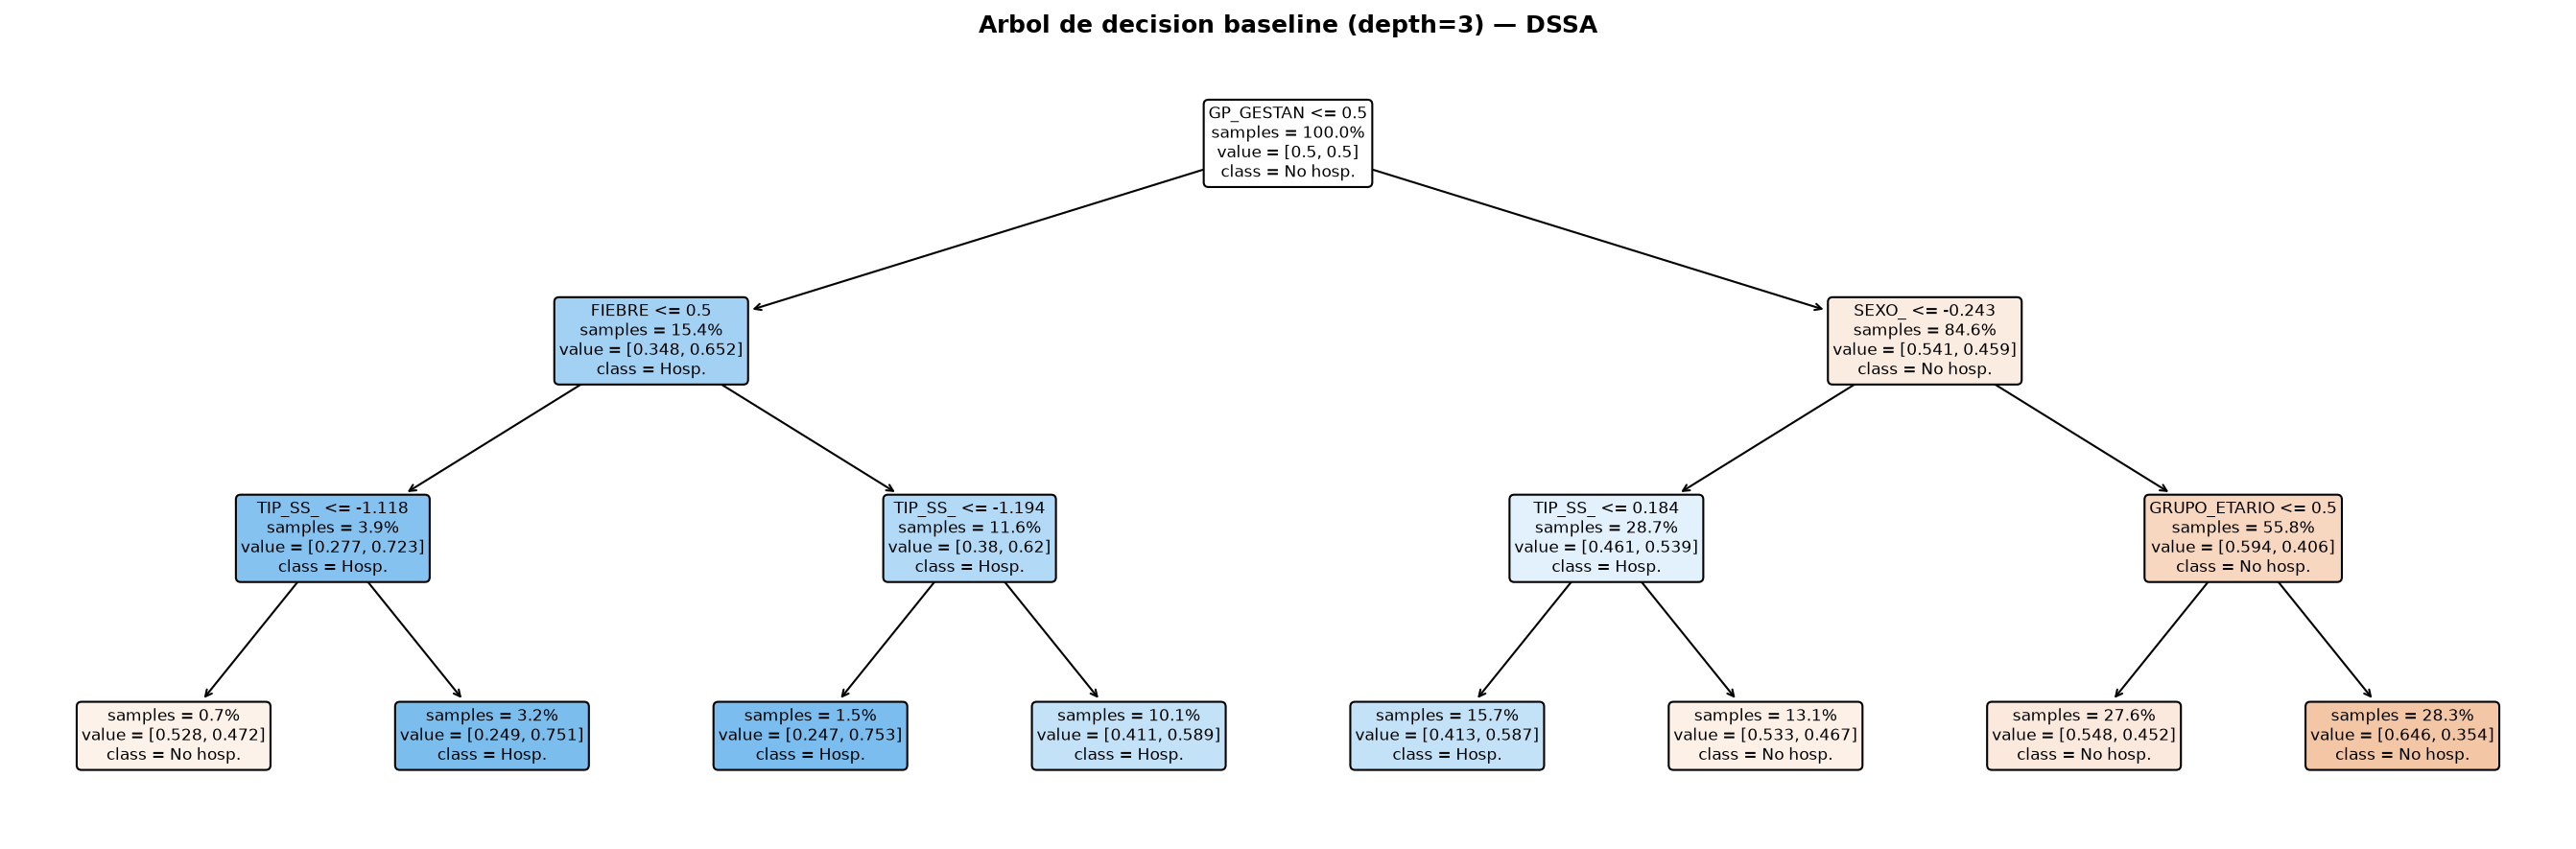

  RAM en uso: 345 MB


In [6]:
CP_BASELINE = CHECKPOINTS / 'baseline_DSSA.pkl'

if checkpoint_existe(CP_BASELINE):
    print('Baselines ya entrenados — cargando checkpoint...')
    dummy, dt = joblib.load(CP_BASELINE)
else:
    dummy = make_pipe(DummyClassifier(strategy='most_frequent'), smote=False)
    dt    = make_pipe(DecisionTreeClassifier(max_depth=3, min_samples_leaf=50,
        class_weight='balanced', random_state=RANDOM_STATE), smote=False)
    dummy.fit(X_train, y_train)
    dt.fit(X_train, y_train)
    guardar_checkpoint((dummy, dt), CP_BASELINE, 'baselines')

for nombre, pipe in [('Dummy', dummy), ('Decision Tree depth=3', dt)]:
    y_pred = pipe.predict(X_test)
    print(f'\n=== {nombre} ===')
    print(classification_report(y_test, y_pred,
        target_names=['No hosp.', 'Hospitalizado']))

feature_names_out = vars_demo + vars_tiempo + vars_clinicas
fig, ax = plt.subplots(figsize=(18, 6))
plot_tree(dt.named_steps['clf'], feature_names=feature_names_out,
    class_names=['No hosp.', 'Hosp.'], filled=True, rounded=True,
    fontsize=8, ax=ax, impurity=False, proportion=True)
ax.set_title('Arbol de decision baseline (depth=3) — DSSA', fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'sin_signos_baseline_tree.png', dpi=300,
    bbox_inches='tight', facecolor='white')
plt.show()
limpiar_memoria()
memoria_usada()

## 3. Validación cruzada 5-fold estratificada

Se evalúan 9 modelos sobre el conjunto de entrenamiento.
La métrica primaria es **AUC-PR** (Average Precision Score),
que resume la curva Precision-Recall en un solo número.

> **Por qué AUC-PR y no F1 o AUC-ROC en DSSA:**
> - **F1:** depende del umbral de clasificación por defecto (0.5),
>   que es inadecuado para desbalance 96/4.
> - **AUC-ROC:** puede ser engañosamente alto (>0.85) incluso para
>   modelos mediocres cuando el desbalance es severo.
> - **AUC-PR:** evalúa la capacidad del modelo de rankear correctamente
>   los positivos en toda la gama de umbrales, penalizando duramente
>   los falsos negativos. Un modelo sin información tiene AUC-PR igual
>   a la prevalencia (0.039) — el techo informativo es 1.0.

In [7]:
CP_CV = CHECKPOINTS / 'cv_DSSA.pkl'

portafolio_cv = {
    'Dummy':             make_pipe(DummyClassifier(strategy='most_frequent'), smote=False),
    'Decision Tree':     make_pipe(DecisionTreeClassifier(max_depth=3,
                             class_weight='balanced', random_state=RANDOM_STATE), smote=False),
    'Logistic Reg.':     make_pipe(LogisticRegression(max_iter=500, C=1.0,
                             random_state=RANDOM_STATE, n_jobs=1)),
    'Random Forest':     make_pipe(RandomForestClassifier(n_estimators=100,
                             max_depth=8, random_state=RANDOM_STATE, n_jobs=1)),
    'Extra Trees':       make_pipe(ExtraTreesClassifier(n_estimators=100,
                             max_depth=8, random_state=RANDOM_STATE, n_jobs=1)),
    'Gradient Boosting': make_pipe(GradientBoostingClassifier(n_estimators=100,
                             learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)),
    'XGBoost':           make_pipe(XGBClassifier(n_estimators=100, learning_rate=0.05,
                             max_depth=5, eval_metric='logloss', tree_method='hist',
                             random_state=RANDOM_STATE, n_jobs=1, verbosity=0)),
    'LightGBM':          make_pipe(LGBMClassifier(n_estimators=100, learning_rate=0.05,
                             max_depth=6, num_leaves=31,
                             random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
    'CatBoost':          make_pipe(CatBoostClassifier(iterations=100, learning_rate=0.05,
                             depth=6, random_seed=RANDOM_STATE, thread_count=1, verbose=0)),
}

portafolio_final = {
    'Dummy':             make_pipe(DummyClassifier(strategy='most_frequent'), smote=False),
    'Decision Tree':     make_pipe(DecisionTreeClassifier(max_depth=3,
                             class_weight='balanced', random_state=RANDOM_STATE), smote=False),
    'Logistic Reg.':     make_pipe(LogisticRegression(max_iter=1000, C=1.0,
                             random_state=RANDOM_STATE)),
    'Random Forest':     make_pipe(RandomForestClassifier(n_estimators=300,
                             max_depth=10, random_state=RANDOM_STATE, n_jobs=1)),
    'Extra Trees':       make_pipe(ExtraTreesClassifier(n_estimators=300,
                             max_depth=10, random_state=RANDOM_STATE, n_jobs=1)),
    'Gradient Boosting': make_pipe(GradientBoostingClassifier(n_estimators=200,
                             learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)),
    'XGBoost':           make_pipe(XGBClassifier(n_estimators=300, learning_rate=0.05,
                             max_depth=5, eval_metric='logloss', tree_method='hist',
                             random_state=RANDOM_STATE, n_jobs=1, verbosity=0)),
    'LightGBM':          make_pipe(LGBMClassifier(n_estimators=300, learning_rate=0.05,
                             max_depth=6, num_leaves=31,
                             random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
    'CatBoost':          make_pipe(CatBoostClassifier(iterations=300, learning_rate=0.05,
                             depth=6, random_seed=RANDOM_STATE, thread_count=1, verbose=0)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Métrica primaria DSSA: average_precision (AUC-PR)
# AUC-ROC se incluye como secundaria para comparar con DCSA
scoring = {
    'average_precision': make_scorer(average_precision_score, needs_proba=True),
    'roc_auc':           make_scorer(roc_auc_score, needs_proba=True),
    'balanced_accuracy': make_scorer(balanced_accuracy_score),
    'f1':                make_scorer(f1_score, pos_label=1),
    'precision':         make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall':            make_scorer(recall_score, pos_label=1),
}

if checkpoint_existe(CP_CV):
    print('CV ya calculada — cargando...')
    resultados_cv = joblib.load(CP_CV)
    for nombre, res in resultados_cv.items():
        print(f"  {nombre}: AUC-PR={res['average_precision']['mean']:.3f} +/- {res['average_precision']['std']:.3f}")
else:
    resultados_cv = {}
    for nombre, pipe in portafolio_cv.items():
        CP_MOD = CHECKPOINTS / f'cv_DSSA_{nombre.replace(" ","_").replace(".","")}.pkl'
        if checkpoint_existe(CP_MOD):
            print(f'  {nombre}: ya calculado, cargando...')
            resultados_cv[nombre] = joblib.load(CP_MOD)
        else:
            print(f'  Entrenando {nombre}...', end=' ', flush=True)
            cv_res = cross_validate(pipe, X_train, y_train,
                cv=cv, scoring=scoring, n_jobs=1)
            resultados_cv[nombre] = {
                m: {'mean': cv_res[f'test_{m}'].mean(),
                    'std':  cv_res[f'test_{m}'].std()}
                for m in scoring
            }
            guardar_checkpoint(resultados_cv[nombre], CP_MOD, nombre)
            print(f"AUC-PR={resultados_cv[nombre]['average_precision']['mean']:.3f}")
        limpiar_memoria()
        memoria_usada()
    guardar_checkpoint(resultados_cv, CP_CV, 'CV completa DSSA')

memoria_usada()

  Entrenando Dummy...   Guardado Dummy: cv_DSSA_Dummy.pkl (0.0 MB)
AUC-PR=0.039
  RAM en uso: 349 MB
  Entrenando Decision Tree...   Guardado Decision Tree: cv_DSSA_Decision_Tree.pkl (0.0 MB)
AUC-PR=0.079
  RAM en uso: 348 MB
  Entrenando Logistic Reg....   Guardado Logistic Reg.: cv_DSSA_Logistic_Reg.pkl (0.0 MB)
AUC-PR=0.080
  RAM en uso: 348 MB
  Entrenando Random Forest...   Guardado Random Forest: cv_DSSA_Random_Forest.pkl (0.0 MB)
AUC-PR=0.085
  RAM en uso: 350 MB
  Entrenando Extra Trees...   Guardado Extra Trees: cv_DSSA_Extra_Trees.pkl (0.0 MB)
AUC-PR=0.097
  RAM en uso: 353 MB
  Entrenando Gradient Boosting...   Guardado Gradient Boosting: cv_DSSA_Gradient_Boosting.pkl (0.0 MB)
AUC-PR=0.084
  RAM en uso: 354 MB
  Entrenando XGBoost...   Guardado XGBoost: cv_DSSA_XGBoost.pkl (0.0 MB)
AUC-PR=0.088
  RAM en uso: 357 MB
  Entrenando LightGBM...   Guardado LightGBM: cv_DSSA_LightGBM.pkl (0.0 MB)
AUC-PR=0.101
  RAM en uso: 349 MB
  Entrenando CatBoost...   Guardado CatBoost: cv_DSS

## 4. Resultados de validación cruzada

Los resultados se analizan después de ejecutar la celda anterior.
Los patrones esperados y su interpretación:

**Piso de referencia — prevalencia (3.9%):**
Un modelo sin información tiene AUC-PR igual a la prevalencia base.
El Dummy debe quedar cerca de este piso. Todo modelo útil debe superarlo
significativamente para tener valor clínico real.

**AUC-ROC engañoso en DSSA:**
Con desbalance severo, el AUC-ROC puede ser alto (>0.80) incluso para
modelos que detectan muy pocos hospitalizados reales. Por eso se reporta
como métrica secundaria — la primaria es AUC-PR.

**Separación entre modelos:**
En DSSA la separación entre modelos suele ser mayor que en DCSA
porque el problema es más difícil — pequeñas diferencias en la capacidad
de detectar positivos se amplifican en AUC-PR.

**Trade-off Recall vs Precision:**
En DSSA el Recall (sensibilidad) es clínicamente más crítico que la Precision:
un falso negativo (paciente hospitalizable enviado a casa) tiene consecuencias
más graves que un falso positivo (hospitalización innecesaria).
Los modelos con mayor Recall a costa de menor Precision son preferibles
clínicamente en este estrato.

,Modelo,AUC_PR,AUC_PR_std,AUC_ROC,Bal_Acc,F1,Precision,Recall
7,LightGBM,0.1009,0.0194,0.5899,0.5663,0.1144,0.0711,0.3015
4,Extra Trees,0.0968,0.0241,0.6232,0.5801,0.1074,0.0616,0.4209
8,CatBoost,0.0952,0.0219,0.6039,0.5606,0.1125,0.0716,0.2692
6,XGBoost,0.0883,0.0167,0.5852,0.5654,0.1088,0.0655,0.3259
3,Random Forest,0.0848,0.0092,0.6047,0.5688,0.1056,0.0618,0.3623
5,Gradient Boosting,0.0840,0.0199,0.5852,0.5607,0.1049,0.0632,0.3137
2,Logistic Reg.,0.0804,0.0129,0.6310,0.6033,0.1092,0.0604,0.5666
1,Decision Tree,0.0789,0.0145,0.5953,0.5724,0.0960,0.0528,0.5423
0,Dummy,0.0392,0.0002,0.5000,0.5000,0.0000,0.0000,0.0000


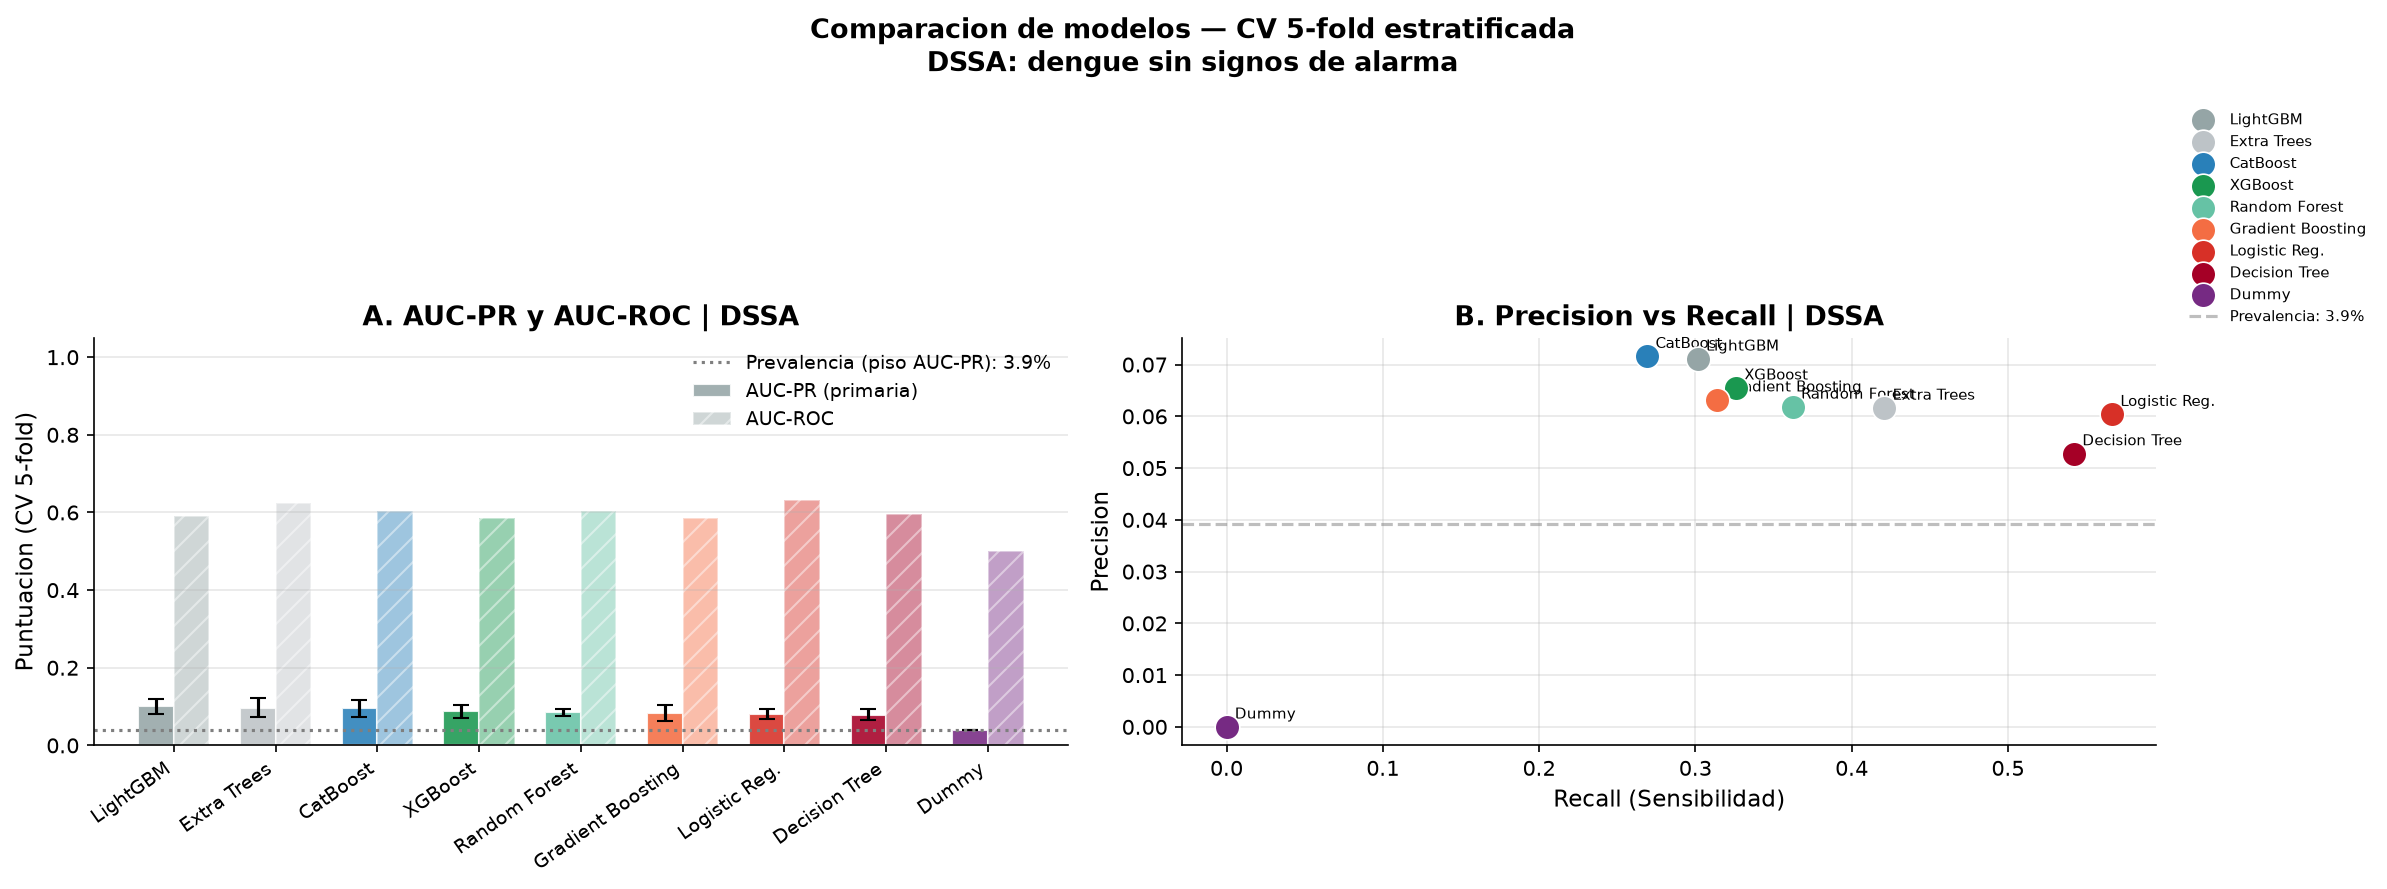

In [8]:
# Tabla resumen CV — ordenada por AUC-PR (métrica primaria DSSA)
filas = []
for nombre, res in resultados_cv.items():
    filas.append({
        'Modelo':    nombre,
        'AUC_PR':    round(res['average_precision']['mean'], 4),
        'AUC_PR_std':round(res['average_precision']['std'], 4),
        'AUC_ROC':   round(res['roc_auc']['mean'], 4),
        'Bal_Acc':   round(res['balanced_accuracy']['mean'], 4),
        'F1':        round(res['f1']['mean'], 4),
        'Precision': round(res['precision']['mean'], 4),
        'Recall':    round(res['recall']['mean'], 4),
    })
tabla_cv = pd.DataFrame(filas).sort_values('AUC_PR', ascending=False)
display(tabla_cv)
tabla_cv.to_csv(OUT_TAB / 'cv_DSSA.csv', index=False)

colores_m = ['#95A5A6','#BDC3C7','#2980B9','#1A9850','#66C2A5',
             '#F46D43','#D73027','#A50026','#762A83']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
x  = np.arange(len(tabla_cv))
w  = 0.35
ax.bar(x - w/2, tabla_cv['AUC_PR'], w, yerr=tabla_cv['AUC_PR_std'],
    color=colores_m[:len(tabla_cv)], alpha=0.88, capsize=4,
    label='AUC-PR (primaria)', edgecolor='white')
ax.bar(x + w/2, tabla_cv['AUC_ROC'], w,
    color=colores_m[:len(tabla_cv)], alpha=0.45, capsize=4,
    label='AUC-ROC', edgecolor='white', hatch='//')
# Piso de AUC-PR = prevalencia
prev = y_train.mean()
ax.axhline(prev, color=COLORS['neutral'], linestyle=':',
    linewidth=1.5, label=f'Prevalencia (piso AUC-PR): {prev:.1%}')
ax.set_xticks(x)
ax.set_xticklabels(tabla_cv['Modelo'], rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Puntuacion (CV 5-fold)')
ax.set_title('A. AUC-PR y AUC-ROC | DSSA')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
for i, (_, row) in enumerate(tabla_cv.iterrows()):
    ax.scatter(row['Recall'], row['Precision'], s=140,
        color=colores_m[i], zorder=5,
        edgecolors='white', linewidth=0.8, label=row['Modelo'])
    ax.annotate(row['Modelo'],
        (row['Recall'], row['Precision']),
        fontsize=7, xytext=(4,4), textcoords='offset points')
ax.axhline(prev, color=COLORS['neutral'], linestyle='--',
    alpha=0.5, label=f'Prevalencia: {prev:.1%}')
ax.set_xlabel('Recall (Sensibilidad)')
ax.set_ylabel('Precision')
ax.set_title('B. Precision vs Recall | DSSA')
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.3)

plt.suptitle('Comparacion de modelos — CV 5-fold estratificada\nDSSA: dengue sin signos de alarma',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'sin_signos_cv_comparacion.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 5. Evaluación final en el conjunto de prueba

Los 3 mejores modelos por **AUC-PR-CV** se reentrenan con parámetros
completos (n_estimators=300) y se evalúan **una única vez** sobre el test set.

Se calcula el panel completo de métricas incluyendo **Brier Score**,
que en DSSA es especialmente relevante: con prevalencia 3.9%, una mala
calibración puede hacer que el modelo asigne P=0.03 a casos que
realmente tienen P=0.30 de hospitalización — subestimación que en
clínica equivale a enviar a casa a un paciente de alto riesgo.

> **Nota sobre los umbrales:** el umbral por defecto (0.5) es inadecuado
> para desbalance 96/4 y se analiza explícitamente en la sección 5b.
> Las métricas aquí calculadas con `predict()` usan el umbral 0.5 —
> las métricas clínicamente relevantes son las de la sección de puntos
> de operación.

,Modelo,AUC_PR,AUC_PR_std,AUC_ROC,Bal_Acc,F1,Precision,Recall
7,LightGBM,0.1009,0.0194,0.5899,0.5663,0.1144,0.0711,0.3015
4,Extra Trees,0.0968,0.0241,0.6232,0.5801,0.1074,0.0616,0.4209
8,CatBoost,0.0952,0.0219,0.6039,0.5606,0.1125,0.0716,0.2692
6,XGBoost,0.0883,0.0167,0.5852,0.5654,0.1088,0.0655,0.3259
3,Random Forest,0.0848,0.0092,0.6047,0.5688,0.1056,0.0618,0.3623
5,Gradient Boosting,0.0840,0.0199,0.5852,0.5607,0.1049,0.0632,0.3137
2,Logistic Reg.,0.0804,0.0129,0.6310,0.6033,0.1092,0.0604,0.5666
1,Decision Tree,0.0789,0.0145,0.5953,0.5724,0.0960,0.0528,0.5423
0,Dummy,0.0392,0.0002,0.5000,0.5000,0.0000,0.0000,0.0000


Top 3 por AUC-PR-CV: ['LightGBM', 'Extra Trees', 'CatBoost']
  Entrenando LightGBM (parámetros completos)...
    AUC-PR=0.0709 | Recall=0.0806 | Brier=0.0822
  RAM en uso: 368 MB
  Entrenando Extra Trees (parámetros completos)...
    AUC-PR=0.0957 | Recall=0.3952 | Brier=0.2067
  RAM en uso: 370 MB
  Entrenando CatBoost (parámetros completos)...
    AUC-PR=0.0798 | Recall=0.0323 | Brier=0.0750
  RAM en uso: 377 MB
  Guardado evaluación final DSSA: eval_test_DSSA.pkl (8.8 MB)


,AUC-PR,AUC-ROC,F1,Brier Score,Bal. Acc,Precision,Recall,Specificity
Modelo,,,,,,,,
Extra Trees,0.0957,0.5991,0.1090,0.2067,0.5775,0.0632,0.3952,0.7598
CatBoost,0.0798,0.5947,0.0537,0.0750,0.5127,0.1600,0.0323,0.9931
LightGBM,0.0709,0.6075,0.0855,0.0822,0.5238,0.0909,0.0806,0.9669


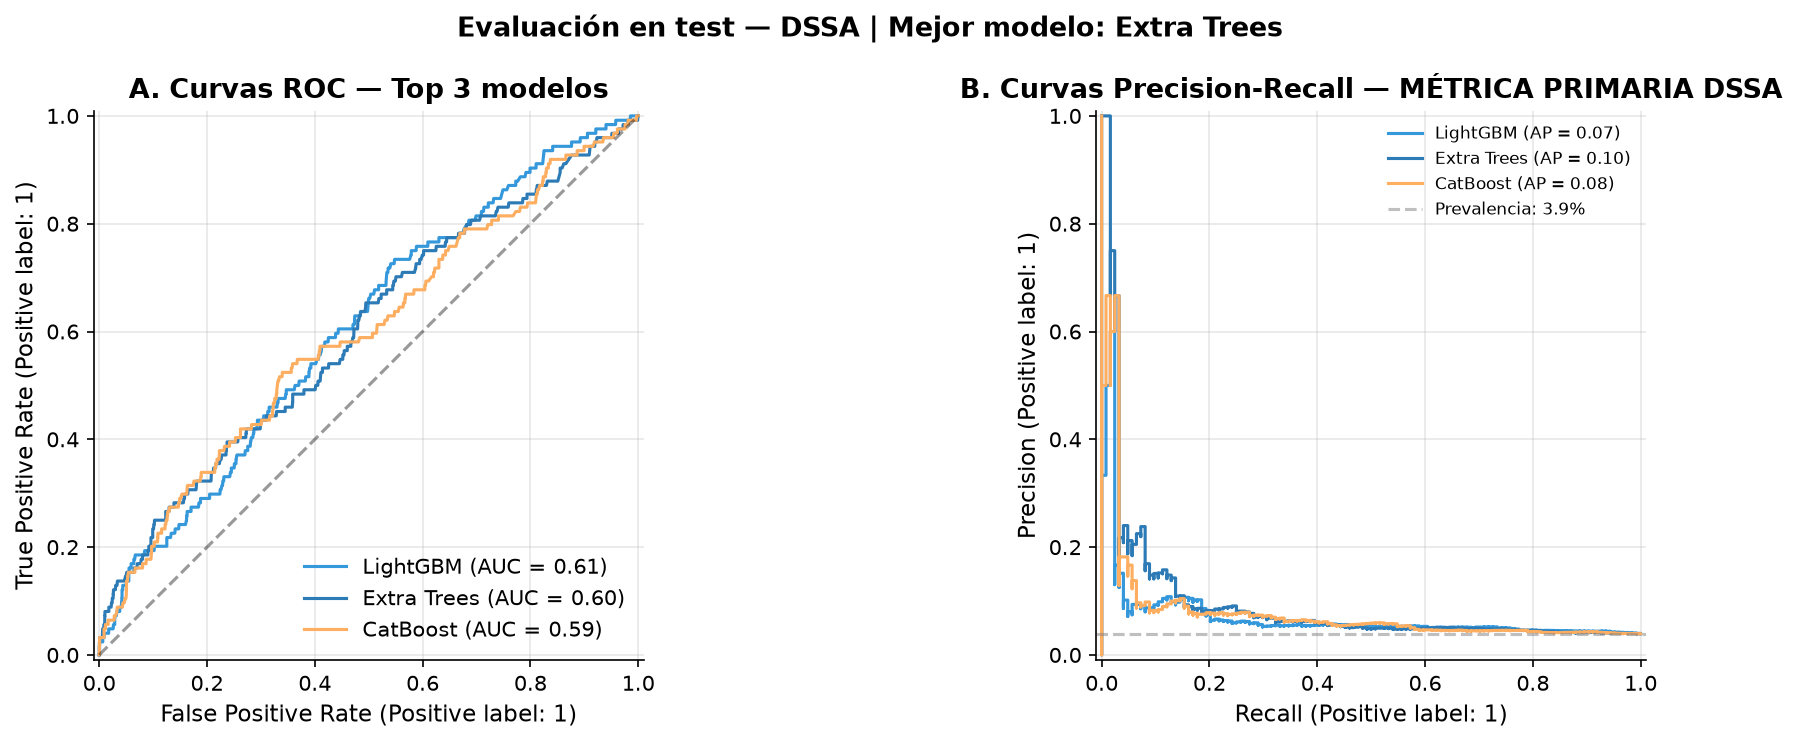

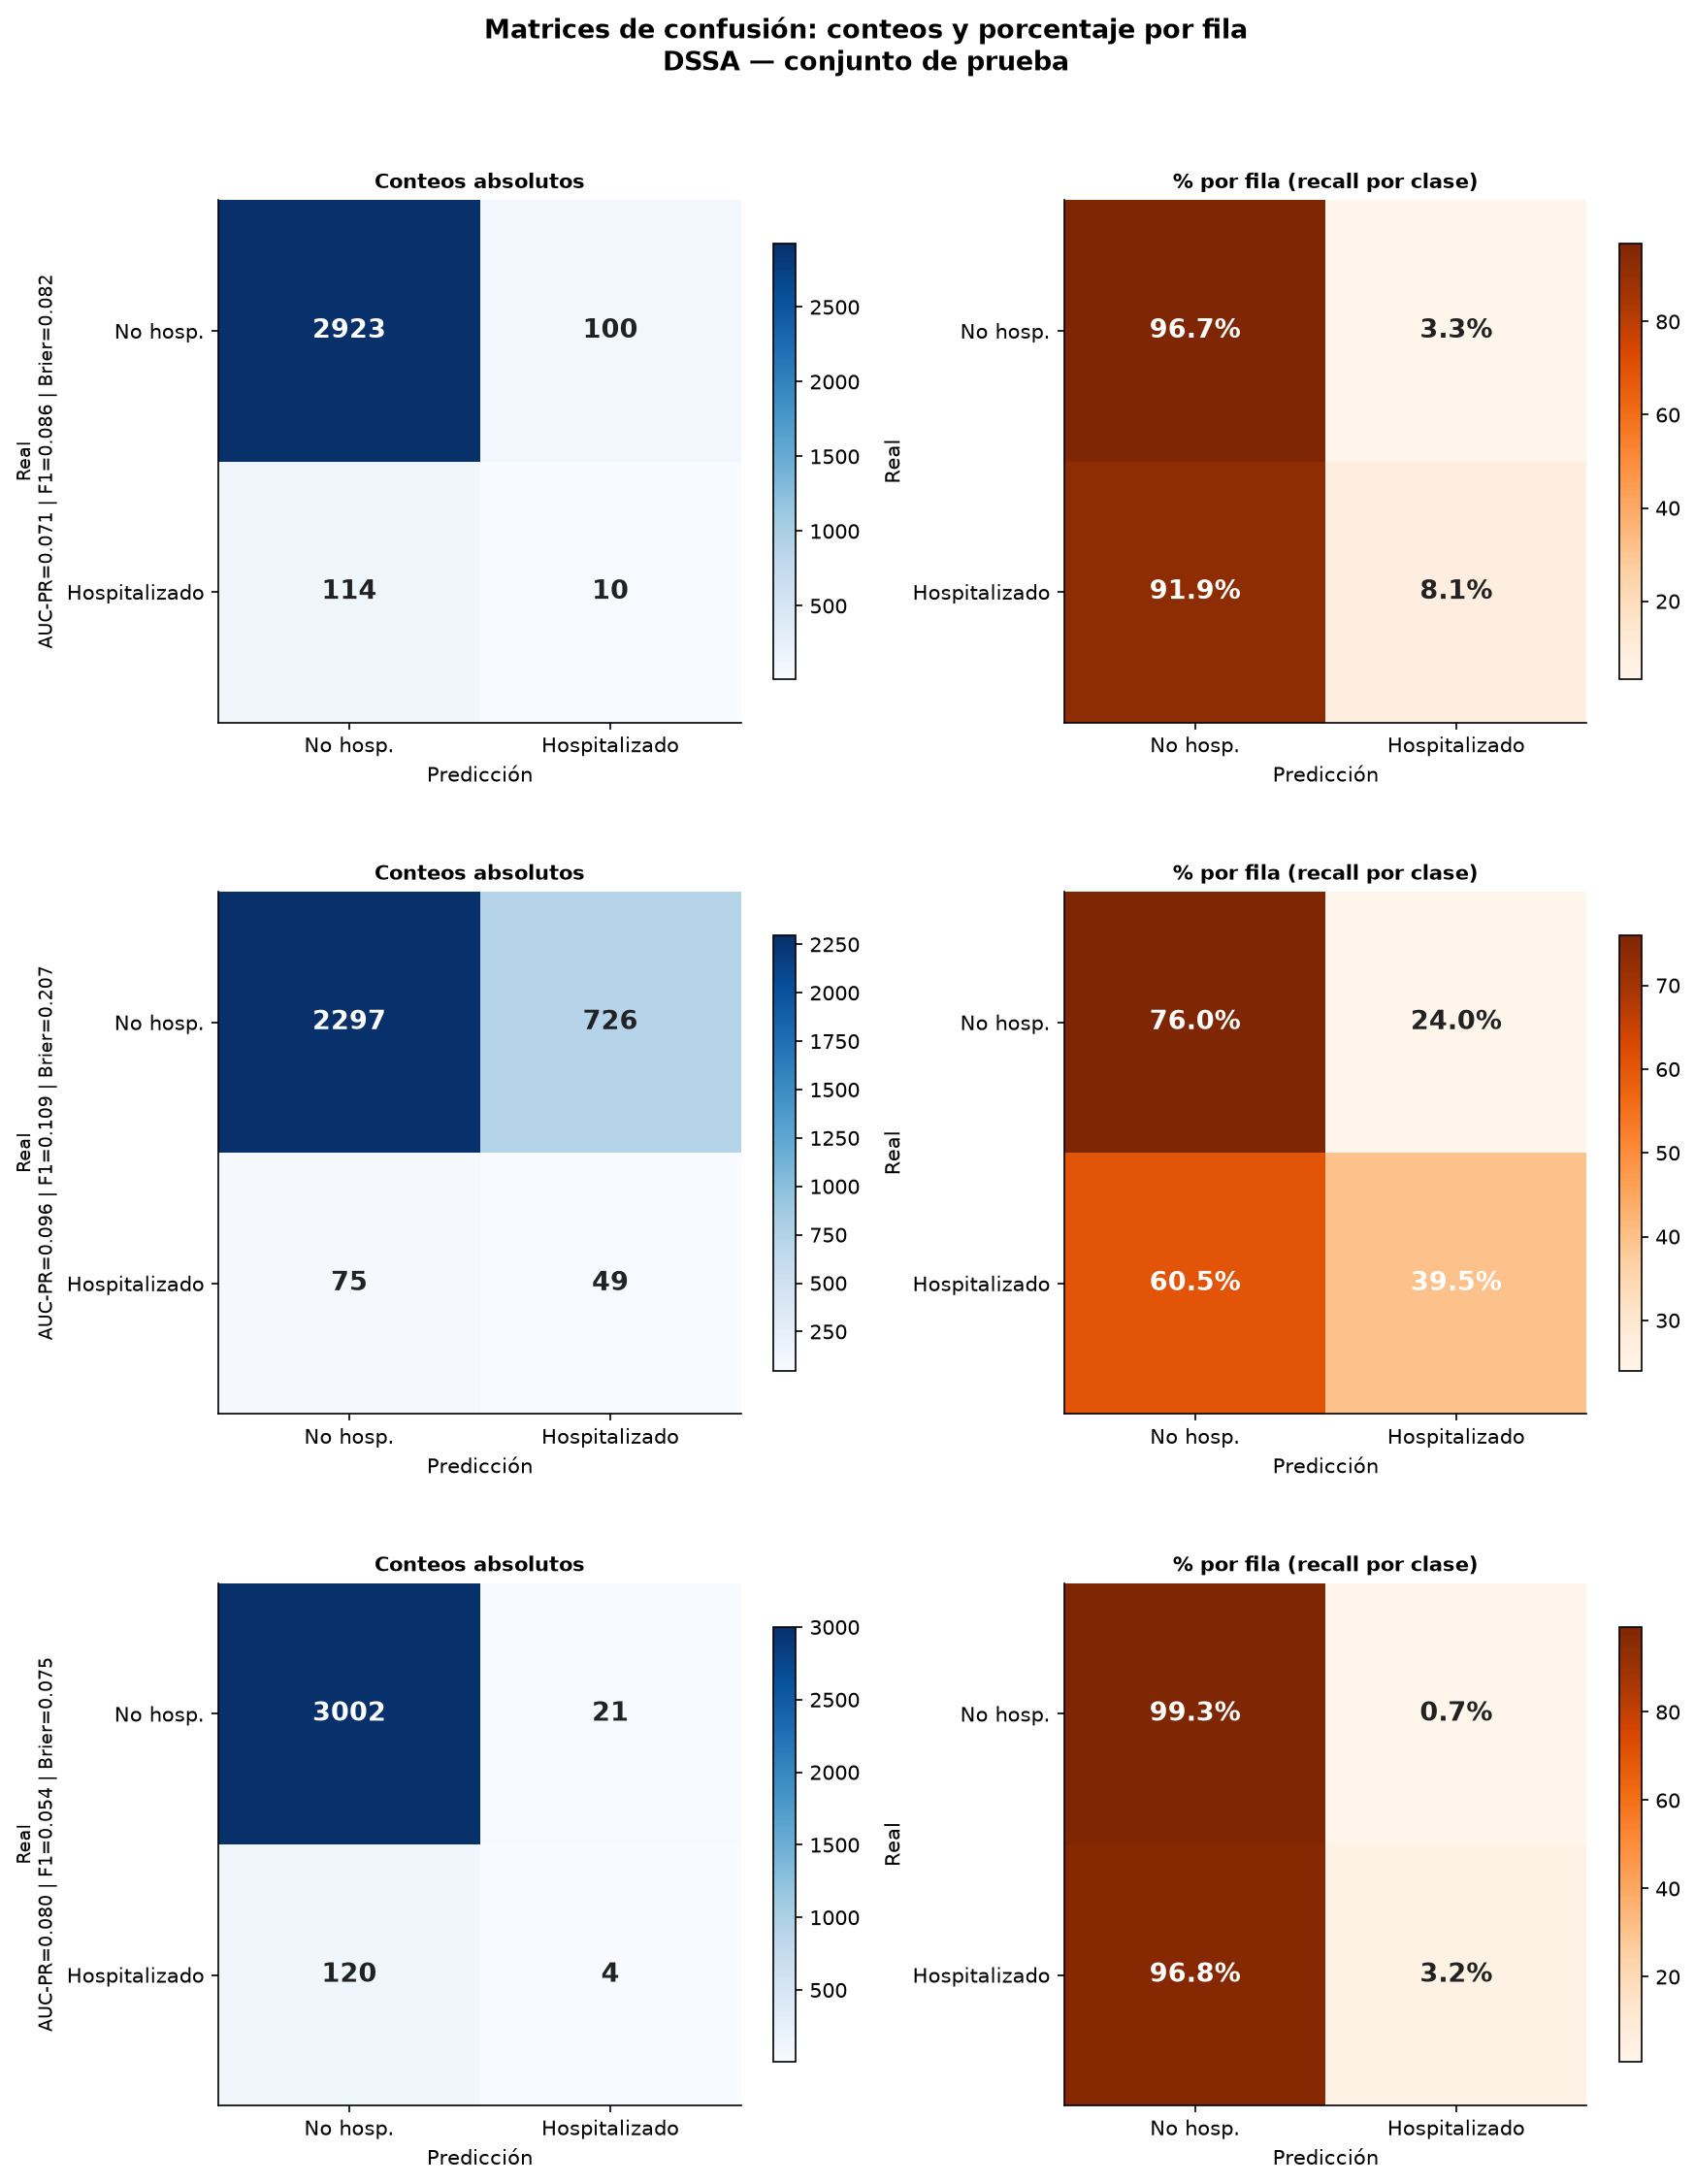

  RAM en uso: 404 MB


In [9]:
from sklearn.metrics import confusion_matrix, brier_score_loss

def plot_confusion_matrix_dual(y_true, y_pred, y_prob, nombre, axes):
    """
    Matrices de confusión duales: conteos absolutos y porcentaje por fila.
    En DSSA el porcentaje por fila es especialmente informativo:
    con 96/4, los conteos absolutos pueden ocultar el rendimiento real
    sobre la clase positiva (hospitalizados).
    """
    cm     = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    etiq   = ['No hosp.', 'Hospitalizado']
    for ax, datos, fmt, cmap, subtit in zip(
        axes,
        [cm, cm_pct], ['{:.0f}', '{:.1f}%'],
        [plt.cm.Blues, plt.cm.Oranges],
        ['Conteos absolutos', '% por fila (recall por clase)']
    ):
        im = ax.imshow(datos, interpolation='nearest', cmap=cmap)
        plt.colorbar(im, ax=ax, shrink=0.75)
        thresh = datos.max() / 2
        for i in range(2):
            for j in range(2):
                color = 'white' if datos[i,j] > thresh else '#222222'
                ax.text(j, i, fmt.format(datos[i,j]),
                    ha='center', va='center', fontsize=13, fontweight='bold', color=color)
        ax.set_xticks([0,1]); ax.set_yticks([0,1])
        ax.set_xticklabels(etiq, fontsize=10)
        ax.set_yticklabels(etiq, fontsize=10)
        ax.set_xlabel('Predicción', fontsize=10)
        ax.set_ylabel('Real', fontsize=10)
        ax.set_title(subtit, fontsize=10, fontweight='bold')
    m = calcular_metricas_completas_dssa(y_true, y_pred, y_prob)
    # En DSSA mostrar AUC-PR como métrica primaria en el ylabel
    axes[0].set_ylabel(
        f'Real\nAUC-PR={m["AUC-PR"]:.3f} | F1={m["F1"]:.3f} | Brier={m["Brier Score"]:.3f}',
        fontsize=9)

CP_EVAL = CHECKPOINTS / 'eval_test_DSSA.pkl'

filas = []
for nombre, res in resultados_cv.items():
    filas.append({'Modelo':    nombre,
        'AUC_PR':    round(res['average_precision']['mean'], 4),
        'AUC_PR_std':round(res['average_precision']['std'], 4),
        'AUC_ROC':   round(res['roc_auc']['mean'], 4),
        'Bal_Acc':   round(res['balanced_accuracy']['mean'], 4),
        'F1':        round(res['f1']['mean'], 4),
        'Precision': round(res['precision']['mean'], 4),
        'Recall':    round(res['recall']['mean'], 4),
    })
tabla_cv = pd.DataFrame(filas).sort_values('AUC_PR', ascending=False)
display(tabla_cv)
tabla_cv.to_csv(OUT_TAB / 'cv_DSSA.csv', index=False)

if checkpoint_existe(CP_EVAL):
    print('Evaluación final ya calculada — cargando checkpoint...')
    saved      = joblib.load(CP_EVAL)
    tabla_test = saved['tabla_test']
    entrenados = saved['entrenados']
    mejor      = saved['mejor']
    display(tabla_test)
else:
    # Seleccionar top 3 por AUC-PR — métrica primaria DSSA
    top3 = (tabla_cv[~tabla_cv['Modelo'].isin(['Dummy','Decision Tree'])]
        .head(3)['Modelo'].tolist())
    print(f'Top 3 por AUC-PR-CV: {top3}')
    entrenados, res_test = {}, []
    for nombre in top3:
        pipe = portafolio_final[nombre]
        print(f'  Entrenando {nombre} (parámetros completos)...')
        pipe.fit(X_train, y_train)
        y_prob = pipe.predict_proba(X_test)[:, 1]
        y_pred = pipe.predict(X_test)
        m = calcular_metricas_completas_dssa(y_test, y_pred, y_prob)
        m['Modelo'] = nombre
        res_test.append(m)
        entrenados[nombre] = {'pipe': pipe, 'y_prob': y_prob, 'y_pred': y_pred}
        print(f'    AUC-PR={m["AUC-PR"]:.4f} | Recall={m["Recall"]:.4f} | Brier={m["Brier Score"]:.4f}')
        limpiar_memoria()
        memoria_usada()
    # Ordenar por AUC-PR — métrica primaria
    tabla_test = pd.DataFrame(res_test).set_index('Modelo').sort_values('AUC-PR', ascending=False)
    mejor      = tabla_test['AUC-PR'].idxmax()
    guardar_checkpoint({'tabla_test': tabla_test,
        'entrenados': entrenados, 'mejor': mejor},
        CP_EVAL, 'evaluación final DSSA')
    display(tabla_test)
    tabla_test.to_csv(OUT_TAB / 'test_DSSA.csv')

# Curvas ROC y Precision-Recall
# En DSSA el panel B (PR) es el que más importa
colores_top = [COLORS['sin_signos'], COLORS['primary'], COLORS['accent']]
fig, axes   = plt.subplots(1, 2, figsize=(14, 5))
for i, (nombre, res) in enumerate(entrenados.items()):
    RocCurveDisplay.from_predictions(
        y_test, res['y_prob'], name=nombre, color=colores_top[i], ax=axes[0])
    PrecisionRecallDisplay.from_predictions(
        y_test, res['y_prob'], name=nombre, color=colores_top[i], ax=axes[1])
axes[0].plot([0,1],[0,1],'k--',alpha=0.4,label='Aleatorio')
axes[0].set_title('A. Curvas ROC — Top 3 modelos')
axes[0].grid(alpha=0.3)
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', alpha=0.5,
    label=f'Prevalencia: {y_test.mean():.1%}')
axes[1].set_title('B. Curvas Precision-Recall — MÉTRICA PRIMARIA DSSA')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.suptitle(f'Evaluación en test — DSSA | Mejor modelo: {mejor}',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'sin_signos_curvas_roc_pr.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Matrices de confusión duales
n_mod = len(entrenados)
fig, axes = plt.subplots(n_mod, 2, figsize=(12, 5*n_mod))
if n_mod == 1: axes = [axes]
for ax_row, (nombre, res) in zip(axes, entrenados.items()):
    plot_confusion_matrix_dual(
        y_test, res['y_pred'], res['y_prob'], nombre=nombre, axes=ax_row)
plt.suptitle(
    'Matrices de confusión: conteos y porcentaje por fila\nDSSA — conjunto de prueba',
    fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(OUT_FIG / 'sin_signos_confusion_dual.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
memoria_usada()

## 5b. Análisis de Puntos de Operación Clínicos — DSSA

En DSSA el análisis de umbrales es **más crítico que en DCSA** por dos razones:

1. **El umbral por defecto (0.5) es inapropiado:** con 3.9% de prevalencia,
   casi ningún paciente superará P=0.5 — el modelo clasificará a casi todos
   como 'no hospitalizar' independientemente de su riesgo real.
2. **El costo asimétrico de los errores:** un falso negativo en DSSA
   (paciente ambulatorio con dengue que se deteriora en casa) tiene
   consecuencias potencialmente fatales — justifica un umbral más bajo
   que en DCSA.

**Screening-First:** prioridad máxima en DSSA. Se busca el umbral
que garantice Recall ≥ 90% — en DSSA se acepta un umbral más bajo
que el 95% de DCSA porque la señal clínica disponible es más débil.

**Capacity-First:** identifica el Top 5% y Top 10% de mayor riesgo.
En DSSA el enriquecimiento esperado es mayor que en DCSA —
con solo 3.9% de prevalencia base, identificar correctamente los
positivos genera factores de enriquecimiento potencialmente altos (>5x).

Calculando puntos de operación clínicos — Extra Trees...
  Guardado puntos de operación DSSA: operacion_clinica_DSSA.pkl (0.0 MB)

=== PUNTOS DE OPERACIÓN CLÍNICOS — Extra Trees ===
Prevalencia base (test): 3.9%



,Umbral,Recall,Specificity,Precision (PPV),F1,Pacientes alertados,Enriquecimiento
Default (umbral=0.5),0.5000,0.3952,0.7598,0.0632,0.1090,775.0,1.60
Screening-First (Recall≥90%),0.3394,0.9032,0.1449,0.0415,0.0794,2697.0,1.05
Capacity-First (Top 5%),0.6335,0.1452,NaN,0.1091,0.1246,165.0,2.77
Capacity-First (Top 10%),0.5707,0.2016,NaN,0.0794,0.1139,315.0,2.01


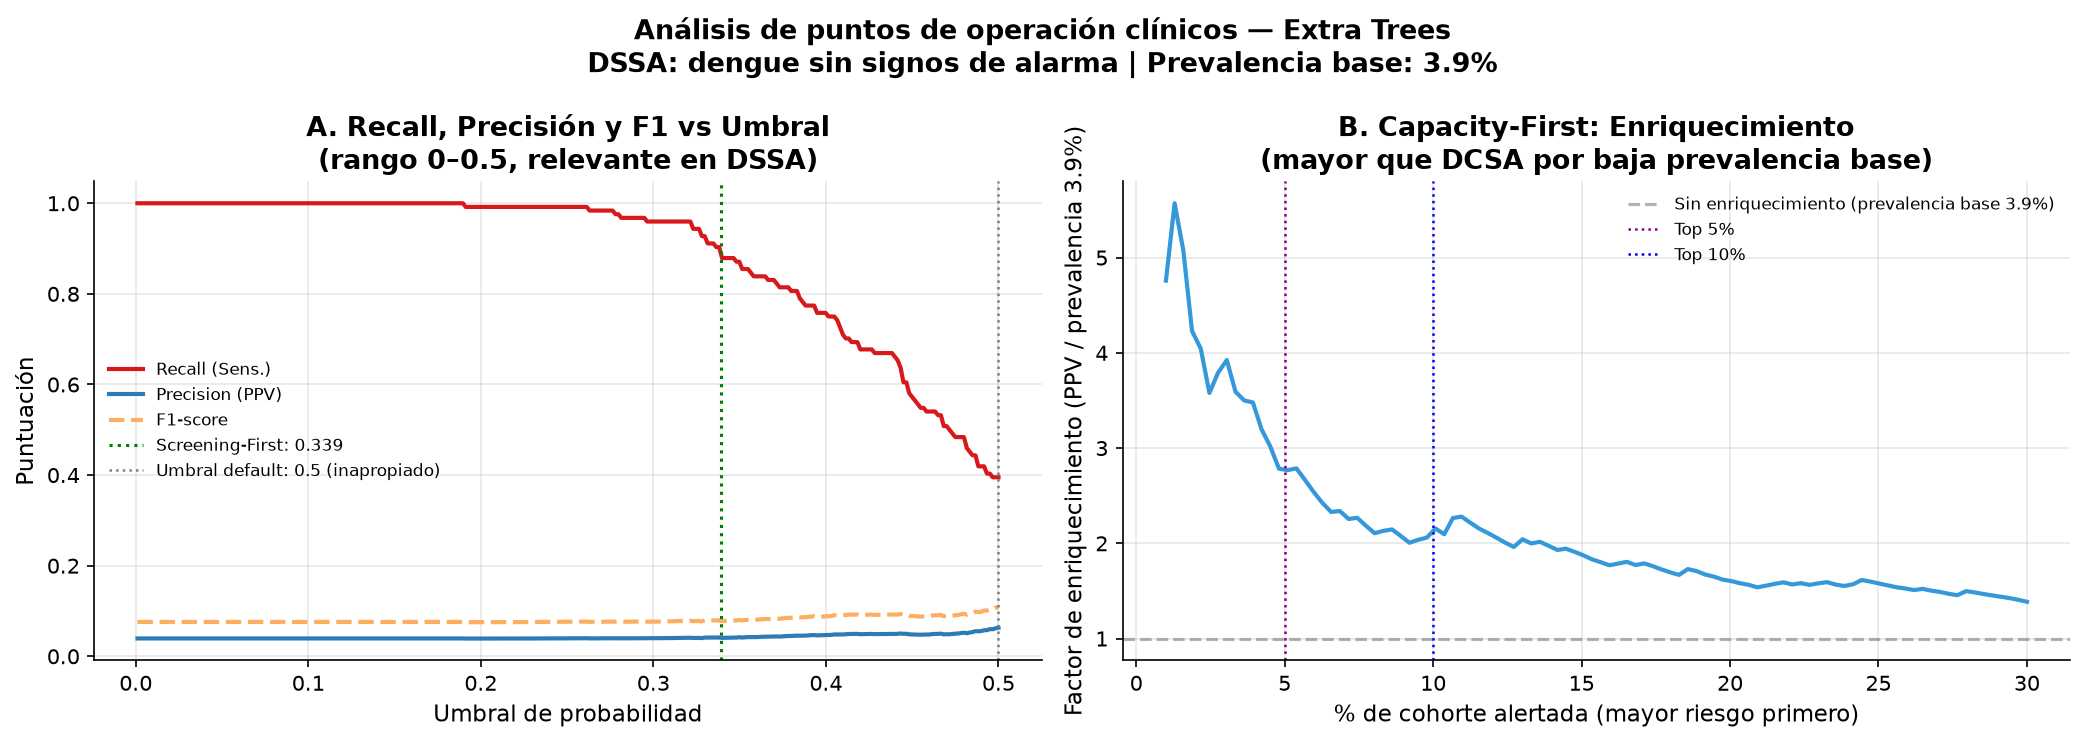

In [10]:
# Análisis de puntos de operación — DSSA
# Diferencias respecto a 03a:
# - Screening-First: Recall >= 90% (no 95%) — señal más débil en DSSA
# - Capacity-First: enriquecimiento esperado mayor por baja prevalencia base
# - El umbral default (0.5) probablemente clasifica todo como negativo
CP_OP = CHECKPOINTS / 'operacion_clinica_DSSA.pkl'

y_prob_mejor = entrenados[mejor]['y_prob']
prev_test    = y_test.mean()

if checkpoint_existe(CP_OP):
    print('Puntos de operación ya calculados — cargando...')
    res_op = joblib.load(CP_OP)
    umbral_screening = res_op['umbral_screening']
    resultados_op    = res_op['resultados_op']
else:
    print(f'Calculando puntos de operación clínicos — {mejor}...')
    thresholds_grid = np.linspace(0.001, 0.99, 2000)

    # Rendimiento con umbral default 0.5
    y_pred_default = (y_prob_mejor >= 0.5).astype(int)
    m_default = calcular_metricas_completas_dssa(y_test, y_pred_default, y_prob_mejor)

    # Screening-First: mayor umbral con Recall >= 90%
    # Se usa 90% en DSSA (no 95%) porque la señal clínica es más débil
    umbral_screening = 0.001
    for t in thresholds_grid:
        y_p_t = (y_prob_mejor >= t).astype(int)
        if recall_score(y_test, y_p_t) >= 0.90:
            umbral_screening = t
        else:
            break

    y_pred_screen = (y_prob_mejor >= umbral_screening).astype(int)
    m_screen = calcular_metricas_completas_dssa(y_test, y_pred_screen, y_prob_mejor)

    resultados_op = {}
    resultados_op['Default (umbral=0.5)'] = {
        'Umbral': 0.5,
        'Recall': round(m_default['Recall'], 4),
        'Specificity': round(m_default['Specificity'], 4),
        'Precision (PPV)': round(m_default['Precision'], 4),
        'F1': round(m_default['F1'], 4),
        'Pacientes alertados': int(y_pred_default.sum()),
        'Enriquecimiento': round(m_default['Precision'] / prev_test, 2) if m_default['Precision'] > 0 else 0,
    }
    resultados_op['Screening-First (Recall≥90%)'] = {
        'Umbral': round(umbral_screening, 4),
        'Recall': round(m_screen['Recall'], 4),
        'Specificity': round(m_screen['Specificity'], 4),
        'Precision (PPV)': round(m_screen['Precision'], 4),
        'F1': round(m_screen['F1'], 4),
        'Pacientes alertados': int(y_pred_screen.sum()),
        'Enriquecimiento': round(m_screen['Precision'] / prev_test, 2),
    }

    for top_pct in [5, 10]:
        cutoff    = np.percentile(y_prob_mejor, 100 - top_pct)
        y_pred_cap = (y_prob_mejor >= cutoff).astype(int)
        ppv_cap   = precision_score(y_test, y_pred_cap, zero_division=0)
        rec_cap   = recall_score(y_test, y_pred_cap)
        enrichment = ppv_cap / prev_test if prev_test > 0 else 0
        resultados_op[f'Capacity-First (Top {top_pct}%)'] = {
            'Umbral': round(cutoff, 4),
            'Recall': round(rec_cap, 4),
            'Specificity': None,
            'Precision (PPV)': round(ppv_cap, 4),
            'F1': round(f1_score(y_test, y_pred_cap), 4),
            'Pacientes alertados': int(y_pred_cap.sum()),
            'Enriquecimiento': round(enrichment, 2),
        }

    guardar_checkpoint(
        {'umbral_screening': umbral_screening, 'resultados_op': resultados_op},
        CP_OP, 'puntos de operación DSSA')

tabla_op = pd.DataFrame(resultados_op).T
print(f'\n=== PUNTOS DE OPERACIÓN CLÍNICOS — {mejor} ===')
print(f'Prevalencia base (test): {prev_test:.1%}\n')
display(tabla_op)
tabla_op.to_csv(OUT_TAB / 'operacion_clinica_DSSA.csv')

# Visualización: curva Recall vs Precision por umbral
thresholds_plot = np.linspace(0.001, 0.50, 300)  # DSSA: rango relevante < 0.50
recalls, precisions, f1s = [], [], []
for t in thresholds_plot:
    yp = (y_prob_mejor >= t).astype(int)
    recalls.append(recall_score(y_test, yp))
    precisions.append(precision_score(y_test, yp, zero_division=0))
    f1s.append(f1_score(y_test, yp))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(thresholds_plot, recalls,    color=COLORS['secondary'], linewidth=2, label='Recall (Sens.)')
axes[0].plot(thresholds_plot, precisions, color=COLORS['primary'],   linewidth=2, label='Precision (PPV)')
axes[0].plot(thresholds_plot, f1s,        color=COLORS['accent'],    linewidth=2, linestyle='--', label='F1-score')
axes[0].axvline(umbral_screening, color='green', linestyle=':', linewidth=1.5,
    label=f'Screening-First: {umbral_screening:.3f}')
axes[0].axvline(0.5, color=COLORS['neutral'], linestyle=':', linewidth=1.2,
    label='Umbral default: 0.5 (inapropiado)')
axes[0].set_xlabel('Umbral de probabilidad')
axes[0].set_ylabel('Puntuación')
axes[0].set_title('A. Recall, Precisión y F1 vs Umbral\n(rango 0–0.5, relevante en DSSA)')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Panel B: enriquecimiento
top_pcts    = np.linspace(1, 30, 100)  # DSSA: Top 30% máximo relevante
enrichments = []
for pct in top_pcts:
    cutoff = np.percentile(y_prob_mejor, 100 - pct)
    yp     = (y_prob_mejor >= cutoff).astype(int)
    ppv    = precision_score(y_test, yp, zero_division=0)
    enrichments.append(ppv / prev_test if prev_test > 0 else 0)

axes[1].plot(top_pcts, enrichments, color=COLORS['sin_signos'], linewidth=2)
axes[1].axhline(1.0, color=COLORS['neutral'], linestyle='--', alpha=0.6,
    label='Sin enriquecimiento (prevalencia base 3.9%)')
axes[1].axvline(5,  color='purple', linestyle=':', linewidth=1.2, label='Top 5%')
axes[1].axvline(10, color='blue',   linestyle=':', linewidth=1.2, label='Top 10%')
axes[1].set_xlabel('% de cohorte alertada (mayor riesgo primero)')
axes[1].set_ylabel('Factor de enriquecimiento (PPV / prevalencia 3.9%)')
axes[1].set_title('B. Capacity-First: Enriquecimiento\n(mayor que DCSA por baja prevalencia base)')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.suptitle(
    f'Análisis de puntos de operación clínicos — {mejor}\n'
    'DSSA: dengue sin signos de alarma | Prevalencia base: 3.9%',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'sin_signos_operacion_clinica.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 5c. Análisis de Decisión Clínica (DCA) — DSSA

El DCA en DSSA tiene una interpretación diferente al DCSA:

- **'Treat All' es un competidor débil:** con 3.9% de hospitalización,
  hospitalizar a todos genera un Net Benefit muy bajo — el costo de los
  falsos positivos (96.1% de la cohorte) anula rápidamente el beneficio.
- **El modelo añade valor en un rango amplio de umbrales:** precisamente
  porque 'Treat All' es ineficiente, cualquier modelo con señal clínica
  real supera fácilmente a esta estrategia baseline.
- **Rango relevante de pt:** en DSSA los médicos raramente hospitalizarían
  con P > 0.30 — el rango clínicamente relevante es pt = 0.02–0.20.

El DCA revela si el modelo tiene valor clínico real o si simplemente
supera a 'Treat All' por la baja prevalencia.

  Guardado DCA DSSA: dca_DSSA.pkl (0.0 MB)


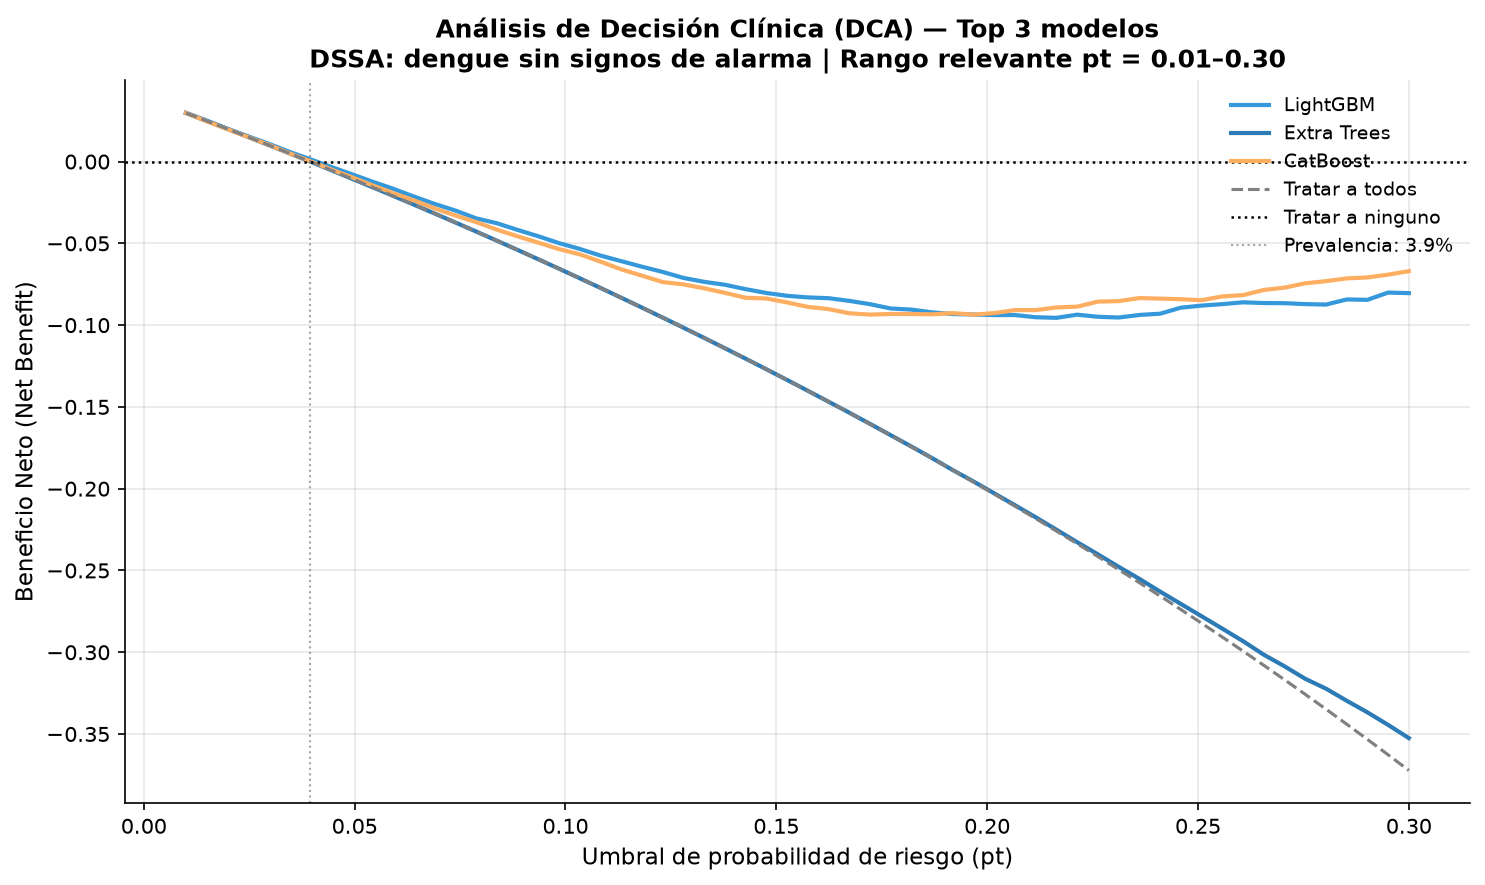

In [11]:
# DCA para DSSA — checkpoint incluido
# Rango de umbrales reducido: 0.01-0.30 (relevante en DSSA con prev. 3.9%)
CP_DCA = CHECKPOINTS / 'dca_DSSA.pkl'

thresholds_dca = np.linspace(0.01, 0.30, 60)  # rango relevante DSSA
modelos_dca    = list(entrenados.keys())[:3]

if checkpoint_existe(CP_DCA):
    print('DCA ya calculado — cargando...')
    dca_data = joblib.load(CP_DCA)
else:
    dca_data = {}
    for nombre in modelos_dca:
        y_p = entrenados[nombre]['y_prob']
        thresh, nb_mod, nb_all = decision_curve_analysis(y_test, y_p, thresholds_dca)
        dca_data[nombre] = {'thresh': thresh, 'nb_mod': nb_mod, 'nb_all': nb_all}
    guardar_checkpoint(dca_data, CP_DCA, 'DCA DSSA')

colores_dca = [COLORS['sin_signos'], COLORS['primary'], COLORS['accent']]
fig, ax = plt.subplots(figsize=(10, 6))

for i, nombre in enumerate(modelos_dca):
    d = dca_data[nombre]
    ax.plot(d['thresh'], d['nb_mod'],
        color=colores_dca[i], linewidth=2, label=nombre)

ax.plot(dca_data[modelos_dca[0]]['thresh'],
        dca_data[modelos_dca[0]]['nb_all'],
        linestyle='--', color='gray', linewidth=1.5, label='Tratar a todos')
ax.axhline(0, linestyle=':', color='black', linewidth=1.2, label='Tratar a ninguno')

# Prevalencia como referencia visual
ax.axvline(prev_test, color=COLORS['neutral'], linestyle=':',
    linewidth=1, alpha=0.7, label=f'Prevalencia: {prev_test:.1%}')

ax.set_xlabel('Umbral de probabilidad de riesgo (pt)', fontsize=11)
ax.set_ylabel('Beneficio Neto (Net Benefit)', fontsize=11)
ax.set_title(
    'Análisis de Decisión Clínica (DCA) — Top 3 modelos\n'
    'DSSA: dengue sin signos de alarma | Rango relevante pt = 0.01–0.30',
    fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(OUT_FIG / 'sin_signos_dca.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 6. Importancia de variables

Se usa **permutation importance** evaluado con **AUC-PR** (no F1)
para ser consistente con la métrica primaria del estrato DSSA.

La importancia mide cuánto cae el AUC-PR al permutar aleatoriamente
cada variable — el impacto real en la capacidad discriminativa del modelo.

### Hipótesis sobre el patrón esperado

En DSSA, donde los signos de alarma tienen baja prevalencia por definición,
se espera que las variables **sociodemográficas** (aseguramiento, estrato)
tengan mayor importancia relativa que en DCSA. Esto reflejaría que la
decisión de hospitalizar a un paciente 'sin signos' está influenciada
por el contexto de acceso al sistema más que por la clínica pura.

> Si esto se confirma, tiene implicaciones éticas importantes:
> el modelo puede estar codificando inequidades de acceso en lugar
> de señales de gravedad clínica real.

In [12]:
# Liberar todo lo que no se necesita antes del cálculo intensivo
limpiar_memoria()
import gc; gc.collect()
memoria_usada()

  RAM en uso: 403 MB


In [ ]:
CP_IMP = CHECKPOINTS / 'importancia_DSSA.pkl'

limpiar_memoria()
import gc; gc.collect()
memoria_usada()

vars_demograficas = ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_','GP_GESTAN','GRUPO_ETARIO']

if checkpoint_existe(CP_IMP):
    print('Importancia ya calculada — cargando checkpoint...')
    df_imp = joblib.load(CP_IMP)
else:
    pipe_m = entrenados[mejor]['pipe']
    print(f'Calculando permutation importance: {mejor}...')
    print('  scoring=average_precision (AUC-PR) — metrica primaria DSSA')
    print('  n_jobs=1 y n_repeats=10 para controlar RAM')

    perm = permutation_importance(
        pipe_m, X_test, y_test,
        n_repeats=10,
        random_state=RANDOM_STATE,
        scoring='average_precision',  # AUC-PR, no F1
        n_jobs=1)

    df_imp = pd.DataFrame({
        'Variable':    FEATURES,
        'Importancia': perm.importances_mean,
        'Std':         perm.importances_std,
    }).sort_values('Importancia', ascending=False)

    df_imp['Tipo'] = [
        'Signo de alarma'  if v in SIGNOS_ALARMA
        else ('Sintoma general' if v in SINTOMAS_GENERALES
        else ('Demografica'     if v in vars_demograficas
        else  'Estacionalidad'))
        for v in df_imp['Variable']
    ]
    df_imp = df_imp[df_imp['Variable'] != 'AÑO'].copy()
    guardar_checkpoint(df_imp, CP_IMP, 'importancia')
    limpiar_memoria(perm)

df_imp = df_imp[df_imp['Variable'] != 'AÑO'].copy()

color_tipo = {
    'Signo de alarma': COLORS['con_signos'],
    'Sintoma general': COLORS['sin_signos'],
    'Demografica':     COLORS['accent'],
    'Estacionalidad':  COLORS['neutral'],
}
df_top    = df_imp.head(15)
colores_b = [color_tipo[t] for t in df_top['Tipo']]

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(
    df_top['Variable'][::-1], df_top['Importancia'][::-1],
    xerr=df_top['Std'][::-1], color=colores_b[::-1],
    capsize=4, alpha=0.87, edgecolor='white', height=0.6
)
for bar, (_, row) in zip(bars, df_top[::-1].iterrows()):
    ax.text(
        bar.get_width() + row['Std'] + 0.0005,
        bar.get_y() + bar.get_height()/2,
        f"{row['Importancia']:.4f}",
        va='center', fontsize=8, color='#444444'
    )
leyenda = [mpatches.Patch(color=c, label=t)
    for t,c in color_tipo.items() if t in df_top['Tipo'].values]
ax.legend(handles=leyenda, loc='lower right', fontsize=9)
ax.set_xlabel('Reduccion en AUC-PR al permutar (permutation importance)', fontsize=11)
ax.set_title(
    f'Importancia de variables — {mejor}\n'
    'Dengue sin signos de alarma (DSSA) · n_repeats=10',
    fontsize=12, fontweight='bold')
ax.axvline(0, color=COLORS['neutral'], linewidth=0.8, alpha=0.5)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
fig.savefig(OUT_FIG / 'sin_signos_importancia.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print('\nImportancia promedio por tipo:')
display(df_imp.groupby('Tipo')['Importancia']
    .agg(['mean','max','count']).round(4)
    .sort_values('mean', ascending=False))

df_imp.to_csv(OUT_TAB / 'importancia_DSSA.csv', index=False)
guardar_checkpoint({
    'modelo':      mejor,
    'pipeline':    entrenados[mejor]['pipe'],
    'features':    FEATURES,
    'tabla_test':  tabla_test,
    'importancia': df_imp},
    CHECKPOINTS / 'mejor_modelo_DSSA.pkl', 'modelo final')
print(f'Listo: {mejor}')
memoria_usada()

  RAM en uso: 406 MB
Calculando permutation importance: Extra Trees...
  scoring=average_precision (AUC-PR) — metrica primaria DSSA
  n_jobs=1 y n_repeats=10 para controlar RAM


## 7. Curvas de aprendizaje

Con desbalance 96/4, las curvas de aprendizaje en DSSA son especialmente
informativas sobre la suficiencia de datos positivos:

- Si la curva de validación sigue creciendo, se necesitan más casos
  hospitalizados (positivos) — la clase mayoritaria ya tiene suficientes.
- Si el techo se alcanza con pocos casos, el límite es la señal clínica
  disponible en el formulario SIVIGILA para este estrato.

### Diagnóstico global: techo informativo

Se espera que las curvas se estabilicen relativamente pronto,
dado que la señal clínica en DSSA es débil por definición:
estos pacientes no tienen signos de alarma OMS y la decisión de
hospitalización depende de factores contextuales no capturados en el formulario.

In [ ]:
from sklearn.model_selection import learning_curve

CP_LC = CHECKPOINTS / 'learning_curves_DSSA.pkl'

if checkpoint_existe(CP_LC):
    print('Curvas de aprendizaje ya calculadas — cargando checkpoint...')
    lc_data = joblib.load(CP_LC)
else:
    top3_nombres_lc = tabla_test.head(3)['Modelo'].tolist()
    train_sizes     = np.linspace(0.10, 1.0, 10)
    lc_data = {}
    for nombre in top3_nombres_lc:
        pipe = portafolio_final[nombre]
        print(f'Calculando learning curve: {nombre}...', flush=True)
        train_sz, train_scores, val_scores = learning_curve(
            pipe, X_train, y_train,
            train_sizes=train_sizes,
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
            scoring='average_precision',  # AUC-PR — métrica primaria DSSA
            n_jobs=1, return_times=False
        )
        lc_data[nombre] = {
            'train_sz':     train_sz,
            'train_scores': train_scores,
            'val_scores':   val_scores,
        }
        print(f'  val AUC-PR={val_scores.mean(axis=1)[-1]:.3f}')
        limpiar_memoria()
        memoria_usada()
    guardar_checkpoint(lc_data, CP_LC, 'learning curves DSSA')

top3_nombres = list(lc_data.keys())
colores_modelos = {
    top3_nombres[0]: {'train': '#D7191C', 'val': '#2C7BB6'},
    top3_nombres[1]: {'train': '#E67E22', 'val': '#1A9850'},
    top3_nombres[2]: {'train': '#8E44AD', 'val': '#16A085'},
}
estilos_linea = ['-', '--', ':']
offsets_texto = [0.005, -0.005, 0.012]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax_train, ax_val = axes

for idx, nombre in enumerate(top3_nombres):
    d          = lc_data[nombre]
    train_sz   = d['train_sz']
    train_mean = d['train_scores'].mean(axis=1)
    train_std  = d['train_scores'].std(axis=1)
    val_mean   = d['val_scores'].mean(axis=1)
    val_std    = d['val_scores'].std(axis=1)
    ls         = estilos_linea[idx]
    c_train    = colores_modelos[nombre]['train']
    c_val      = colores_modelos[nombre]['val']

    ax_train.plot(train_sz, train_mean, color=c_train, linewidth=2,
        linestyle=ls, marker='o', markersize=5, label=nombre)
    ax_train.fill_between(train_sz, train_mean-train_std, train_mean+train_std,
        alpha=0.10, color=c_train)

    ax_val.plot(train_sz, val_mean, color=c_val, linewidth=2,
        linestyle=ls, marker='s', markersize=5, label=nombre)
    ax_val.fill_between(train_sz, val_mean-val_std, val_mean+val_std,
        alpha=0.10, color=c_val)

    aucp_test = tabla_test[tabla_test['Modelo']==nombre]['AUC_PR'].values[0]
    ax_val.axhline(aucp_test, linestyle='dotted', color=c_val, linewidth=1.2, alpha=0.6)
    ax_val.text(0.15, aucp_test + offsets_texto[idx],
        f'Test {nombre}: {aucp_test:.3f}',
        transform=ax_val.get_yaxis_transform(),
        fontsize=7.5, color=c_val, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                  edgecolor=c_val, alpha=0.7, linewidth=0.8))

    brecha = train_mean[-1] - val_mean[-1]
    if abs(val_mean[-1]-val_mean[-2]) < 0.003: diag = 'techo'
    elif brecha > 0.05: diag = 'sobreajuste'
    else: diag = 'creciendo'
    print(f'  {nombre}: brecha={brecha:.3f} | {diag}')

ax_train.set_title('A. Curvas de entrenamiento\n(AUC-PR sobre datos vistos)', fontweight='bold')
ax_train.set_xlabel('Casos de entrenamiento', fontsize=10)
ax_train.set_ylabel('AUC-PR', fontsize=10)
ax_train.legend(fontsize=9, title='Modelo', title_fontsize=9, loc='upper right')
ax_train.grid(alpha=0.3)
ax_train.text(0.03, 0.04,
    'Curvas altas en train son normales:\nel modelo ve sus propios datos de entrenamiento',
    transform=ax_train.transAxes, fontsize=7.5, color='#555',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#f9f9f9', edgecolor='#ccc', alpha=0.85))

ax_val.set_title('B. Curvas de validacion (CV)\n(AUC-PR sobre datos NO vistos)',
    fontweight='bold')
ax_val.set_xlabel('Casos de entrenamiento', fontsize=10)
ax_val.legend(fontsize=9, title='Modelo', title_fontsize=9, loc='lower right')
ax_val.grid(alpha=0.3)
# Linea de prevalencia como piso de AUC-PR
ax_val.axhline(y_train.mean(), color=COLORS['neutral'], linestyle='--',
    linewidth=1, alpha=0.5, label=f'Piso AUC-PR (prevalencia): {y_train.mean():.1%}')
ax_val.legend(fontsize=8, loc='upper right')
ax_val.text(0.03, 0.04,
    f'Piso de referencia: prevalencia = {y_train.mean():.1%}\n'
    'Un modelo sin info tiene AUC-PR igual a la prevalencia.',
    transform=ax_val.transAxes, fontsize=7.5, color='#555',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#f9f9f9', edgecolor='#ccc', alpha=0.85))

plt.suptitle(
    'Curvas de aprendizaje — Top 3 modelos\n'
    'DSSA: dengue sin signos de alarma | Metrica: AUC-PR',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'sin_signos_learning_curves.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

### Análisis de curvas de aprendizaje — DSSA

**Diagnóstico global:** se analizará después de ejecutar.

**Lo que buscar:**
- Si las curvas de validación se estabilizan pronto → el límite es la
  señal clínica disponible en SIVIGILA para pacientes sin signos de alarma.
- Si siguen creciendo → más casos hospitalizados mejorarían el modelo.
- Si la brecha train/val es grande → sobreajuste, posiblemente por el
  bajo número de positivos que hace el problema más ruidoso.

---

## Síntesis y conclusiones — DSSA

### Naturaleza del problema

El DSSA representa un problema de detección de señal débil en ruido alto:
3.9% de casos hospitalizados sobre un fondo de 96.1% ambulatorios.
La pregunta clínica relevante es identificar ese 3.9% antes de que
se deteriore en casa — un problema de screening, no de clasificación balanceada.

### Comparativa metodológica con DCSA

| Aspecto | DCSA (03a) | DSSA (03c) |
|---------|-----------|----------|
| Métrica primaria | F1-score | **AUC-PR** |
| Piso de referencia | Dummy F1 ≈ 0.787 | **Prevalencia ≈ 3.9%** |
| Umbral clínico | 0.5 (razonable) | **< 0.20 (ajuste necesario)** |
| Enriquecimiento esperado | ~1.5x | **>5x (por baja prevalencia)** |
| Riesgo FN | Alto | **Crítico** |
| DCA 'Treat All' | Competidor fuerte (65% prev.) | **Ineficiente (3.9% prev.)** |

### Hallazgos esperados sobre importancia de variables

A diferencia del DCSA donde los síntomas generales superaron a los signos
de alarma, en DSSA se espera un patrón diferente:
los signos de alarma tienen mayor valor predictivo relativo porque su
presencia en un paciente clasificado como DSSA es una señal inesperada
y potencialmente indicativa de reclasificación o deterioro inminente.

Si las variables demográficas dominan la importancia, indicaría que
la decisión de hospitalización en DSSA está determinada por el contexto
de acceso (estrato, aseguramiento) más que por la clínica — implicación
ética importante para la equidad algorítmica.

### Limitaciones específicas del DSSA

1. **Decisión médica subjetiva:** en DSSA la hospitalización depende más
   del criterio clínico contextual que de signos objetivos universales.
   El modelo aprende ese criterio histórico, con todos sus sesgos.
2. **Desbalance severo:** el 96/4 limita la potencia estadística para
   aprender patrones de la clase positiva — SMOTE mitiga pero no elimina
   esta limitación estructural.
3. **Calibración crítica:** con prevalencia 3.9%, la calibración del modelo
   (Brier Score) es más importante que en DCSA. Un modelo mal calibrado
   puede subestimar sistemáticamente el riesgo real.
4. **Umbral en producción:** el umbral 0.5 es clínicamente inapropiado.
   Desplegar este modelo requiere definir un umbral operacional explícito
   basado en el trade-off Recall/Precision aceptable por el servicio.
5. **Generalización geográfica:** igual que en DCSA, validación externa
   en otros municipios es necesaria antes del despliegue.

**Siguiente:** `03d_validacion_temporal_sin_signos.ipynb`